# 06 — RoPE своими руками: эксперименты

Правило: перед каждой ячейкой с кодом — «Предсказание». Прогноз пишу **до** запуска, после запуска — одна строка «Что увидел».

## Эксперимент 1: RoPE — один и тот же сдвиг в разных местах текста

**Предсказание:** один и тот же $q$, один и тот же $k$; score для позиций (2, 5) и (100, 103) — совпадут или нет? А для (2, 5) и (2, 50)?

_Мой прогноз:_
- Для (2, 5) и (100, 103) – совпадут: потому что разница между ними одинаковая (m-n=3); а для (2, 5) и (2, 50) – не совпадут

**Что увидел:** для (2, 5), (100, 103) и (150, 153) score одинаковый: −10.7468, то есть зависит только от n − m = 3; для (2, 50) другой: −15.7376.

In [12]:
import torch
from rope import rope_angles, apply_rope, sinusoidal_pe

torch.manual_seed(0)
d, T = 64, 200
q, k = torch.randn(d), torch.randn(d)
angles = rope_angles(T, d)
Q = apply_rope(q.expand(1, T, d).clone(), angles)[0]
K = apply_rope(k.expand(1, T, d).clone(), angles)[0]

for m, n in [(2, 5), (100, 103), (150, 153), (2, 50)]:
    print(f"RoPE  m={m:3d} n={n:3d}  n-m={n-m:3d}  score={(Q[m] @ K[n]).item():.4f}")

RoPE  m=  2 n=  5  n-m=  3  score=-10.7468
RoPE  m=100 n=103  n-m=  3  score=-10.7468
RoPE  m=150 n=153  n-m=  3  score=-10.7468
RoPE  m=  2 n= 50  n-m= 48  score=-15.7376


## Эксперимент 2: то же самое с аддитивным синусоидальным PE

**Предсказание:** score $(q + pe_m)\cdot(k + pe_n)$ для (2, 5) и (100, 103) — совпадут или нет? Почему?

_Мой прогноз:_ 
- Не совпадут, потому что этот метод всегда дает разные значения на разных позициях – даже если значения токена одинаковы, но он стоит на разных позициях, то его score тоже будут разными. Совпадение будет только в том случае, если значение токенов одинаковые, как и позиция.

**Что увидел:** score разный: 20.65 / 18.68 / 20.76. После раскрытия скобок q·k и pe_m·pe_n зависят только от расстояния, а перекрёстные q·pe_n и pe_m·k зависят от абсолютных позиций и ломают инвариантность.

In [13]:
pe = sinusoidal_pe(T, d)
for m, n in [(2, 5), (100, 103), (150, 153)]:
    s = (q + pe[m]) @ (k + pe[n])
    print(f"Add PE  m={m:3d} n={n:3d}  n-m={n-m:3d}  score={s.item():.4f}")

Add PE  m=  2 n=  5  n-m=  3  score=20.6502
Add PE  m=100 n=103  n-m=  3  score=18.6800
Add PE  m=150 n=153  n-m=  3  score=20.7631


## Эксперимент 3: как score зависит от расстояния

**Предсказание:** возьми $q = k$ (один и тот же вектор). Как будет меняться score при росте расстояния $\Delta = n - m$ от 0 до 199: постоянен, растёт, в среднем падает, хаотичен?

_Мой прогноз:_ 
- Интуиция подсказывает, что постоянен


**Что увидел:** не постоянен и не хаотичен: при Δ = 0 score максимальный (≈66), дальше с колебаниями в среднем падает до ≈29 к Δ ≈ 150–200. Быстрые пары расходятся по фазе и их вклады гасят друг друга, вместе остаются только медленные пары.

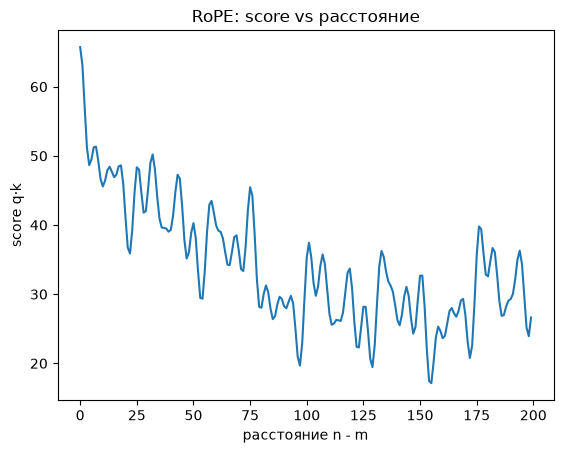

In [14]:
import matplotlib.pyplot as plt

torch.manual_seed(1)
v = torch.randn(d).abs()      # q = k, положительные координаты — чтобы эффект был виден
V = apply_rope(v.expand(1, T, d).clone(), angles)[0]
scores = [(V[0] @ V[delta]).item() for delta in range(T)]

plt.plot(scores)
plt.xlabel("расстояние n - m")
plt.ylabel("score q·k")
plt.title("RoPE: score vs расстояние")
plt.show()